# Libraries

In [1]:
import pandas as pd
from collections import defaultdict

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Multiclass Classification
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Miltilabel Classification
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import classification_report, hamming_loss, jaccard_score

# Time Series Analysis
import holidays

# Data
#### Import

In [85]:
df_merged = pd.read_csv("data/merged_h1_17_24.csv").drop(columns=["StrGlo"])
# StrGlo is only available for one Stampfenbachstrasse Station anyway; for the other 3 it's all NaN for all years 2017-2024
df_merged.head()

,Year,Month,Date,Time,Datetime,Standort,NO,NO2,NOx,O3,PM10,PM2.5,Hr,RainDur,T,WD,WVs,WVv,p,AnzFahrzeuge
0,2017,1,2017-01-01,00:00:00,2017-01-01 00:00:00,Zch_Heubeeribüel,6.96,36.78,24.82,1.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2017,1,2017-01-01,00:00:00,2017-01-01 00:00:00,Zch_Rosengartenstrasse,22.68,39.79,38.99,1.14,193.06,NaN,88.22,0.0,-1.73,194.17,0.36,0.32,977.84,611.0
2,2017,1,2017-01-01,00:00:00,2017-01-01 00:00:00,Zch_Schimmelstrasse,38.59,43.14,53.50,1.43,88.93,70.54,84.78,0.0,-1.33,337.53,NaN,0.99,980.34,344.0
3,2017,1,2017-01-01,00:00:00,2017-01-01 00:00:00,Zch_Stampfenbachstrasse,9.42,37.71,27.27,1.45,105.88,NaN,87.41,0.0,-1.65,292.05,1.36,1.36,977.22,NaN
4,2017,1,2017-01-01,01:00:00,2017-01-01 01:00:00,Zch_Heubeeribüel,13.54,37.11,30.27,1.46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Make Location categorical

In [ ]:
# Example column
col = "Location"  # or any column name

# Simple conversion (auto-infers categories)
df_merged[col] = df_merged[col].astype("category")

# (Optional) define an explicit category order
#df_merged[col] = df_merged[col].cat.set_categorie#s(
#    ["Zch_Heubeeribüel", "Zch_Rosengartenstrasse", "Zch_Schimmelstrasse", "Zch_Stampfenbachstrasse"],
#    ordered=False
#)
df_merged.info()
df_merged.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 275499 entries, 0 to 275498
Data columns (total 20 columns):
 #   Column        Non-Null Count   Dtype   
---  ------        --------------   -----   
 0   Year          275499 non-null  int64   
 1   Month         275499 non-null  int64   
 2   Date          275499 non-null  object  
 3   Time          275499 non-null  object  
 4   Datetime      275499 non-null  object  
 5   Standort      275499 non-null  category
 6   NO            98470 non-null   float64 
 7   NO2           98451 non-null   float64 
 8   NOx           98451 non-null   float64 
 9   O3            99294 non-null   float64 
 10  PM10          77465 non-null   float64 
 11  PM2.5         72835 non-null   float64 
 12  Hr            248821 non-null  float64 
 13  RainDur       234154 non-null  float64 
 14  T             250886 non-null  float64 
 15  WD            232526 non-null  float64 
 16  WVs           195506 non-null  float64 
 17  WVv           232526 non-null

,Year,Month,Date,Time,Datetime,Standort,NO,NO2,NOx,O3,PM10,PM2.5,Hr,RainDur,T,WD,WVs,WVv,p,AnzFahrzeuge
0,2017,1,2017-01-01,00:00:00,2017-01-01 00:00:00,Zch_Heubeeribüel,6.96,36.78,24.82,1.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2017,1,2017-01-01,00:00:00,2017-01-01 00:00:00,Zch_Rosengartenstrasse,22.68,39.79,38.99,1.14,193.06,NaN,88.22,0.0,-1.73,194.17,0.36,0.32,977.84,611.0
2,2017,1,2017-01-01,00:00:00,2017-01-01 00:00:00,Zch_Schimmelstrasse,38.59,43.14,53.50,1.43,88.93,70.54,84.78,0.0,-1.33,337.53,NaN,0.99,980.34,344.0
3,2017,1,2017-01-01,00:00:00,2017-01-01 00:00:00,Zch_Stampfenbachstrasse,9.42,37.71,27.27,1.45,105.88,NaN,87.41,0.0,-1.65,292.05,1.36,1.36,977.22,NaN
4,2017,1,2017-01-01,01:00:00,2017-01-01 01:00:00,Zch_Heubeeribüel,13.54,37.11,30.27,1.46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:

import pandas as pd

def print_missing_whole_days_per_year_Location(df,
                                               date_col="Date",        # date without time (string/date)
                                               datetime_col="Datetime",# full timestamp (if you prefer)
                                               station_col="Location", # station name
                                               use_calendar_year=True  # True=count vs full year; False=count vs observed window
                                              ):
    """
    Prints: 'Year YYYY, Station <Location>: <N> whole days missing'
    Returns a DataFrame with columns: Location, Year, missing_whole_days
    """

    dfi = df.copy()

    # 1) Ensure we have a proper date column to work with
    # If you already have a clean Date column (yyyy-mm-dd) this will just convert it.
    if date_col in dfi.columns:
        dfi[date_col] = pd.to_datetime(dfi[date_col]).dt.date
        # Use Year from column if present and trustworthy; otherwise derive from Datetime/Date
        if "Year" in dfi.columns:
            dfi["Year"] = dfi["Year"].astype(int)
        else:
            if datetime_col in dfi.columns:
                dfi["Year"] = pd.to_datetime(dfi[datetime_col]).dt.year
            else:
                dfi["Year"] = pd.to_datetime(dfi[date_col]).dt.year
    else:
        # Fallback: build Date from Datetime
        dfi[datetime_col] = pd.to_datetime(dfi[datetime_col])
        dfi["Year"] = dfi[datetime_col].dt.year
        dfi[date_col] = dfi[datetime_col].dt.date

    # 2) Iterate station-year combinations
    results = []
    combos = (
        dfi[[station_col, "Year"]]
        .drop_duplicates()
        .sort_values([station_col, "Year"])
        .itertuples(index=False, name=None)
    )

    for station, yr in combos:
        # All observed unique dates for this station-year
        mask = (dfi[station_col] == station) & (dfi["Year"] == yr)
        observed_dates = dfi.loc[mask, date_col].drop_duplicates()

        if observed_dates.empty:
            # Defensive: if no rows but combo exists (unlikely)
            days_in_year = 366 if pd.Timestamp(yr, 12, 31).is_leap_year else 365
            missing_count = days_in_year
        else:
            if use_calendar_year:
                # Full calendar Jan 1 ... Dec 31 of that year
                start = pd.Timestamp(yr, 1, 1)
                end   = pd.Timestamp(yr, 12, 31)
            else:
                # Only between first and last observed date (activation window)
                start = pd.Timestamp(min(observed_dates))
                end   = pd.Timestamp(max(observed_dates))

            full_calendar = pd.date_range(start, end, freq="D").date
            observed_set = set(observed_dates)
            missing_days = [d for d in full_calendar if d not in observed_set]
            missing_count = len(missing_days)

        results.append({
            "Location": station,
            "Year": yr,
            "missing_whole_days": missing_count
        })

    out = pd.DataFrame(results).sort_values(["Location", "Year"]).reset_index(drop=True)

    # 3) Print lines as requested
    for r in out.itertuples(index=False):
        print(f"Year {r.Year}, Station {r.Location}: {r.missing_whole_days} whole days missing")

    return out


In [ ]:
del missing_by_year_station
# Assuming your DataFrame is named df
missing_by_year_station = print_missing_whole_days_per_year_Location(
    df,
    date_col="Date",          # in your screenshot this looks like '2017-01-01'
    datetime_col="Datetime",  # '2017-01-01 00:00:00'
    station_col="Location",
    use_calendar_year=True    # change to False if you prefer the observed window variant
)


Year 2017, Station Zch_Rosengartenstrasse: 0 whole days missing
Year 2018, Station Zch_Rosengartenstrasse: 0 whole days missing
Year 2019, Station Zch_Rosengartenstrasse: 0 whole days missing
Year 2020, Station Zch_Rosengartenstrasse: 0 whole days missing
Year 2021, Station Zch_Rosengartenstrasse: 0 whole days missing
Year 2022, Station Zch_Rosengartenstrasse: 0 whole days missing
Year 2023, Station Zch_Rosengartenstrasse: 0 whole days missing
Year 2024, Station Zch_Rosengartenstrasse: 0 whole days missing
Year 2025, Station Zch_Rosengartenstrasse: 1 whole days missing
Year 2017, Station Zch_Schimmelstrasse: 0 whole days missing
Year 2018, Station Zch_Schimmelstrasse: 0 whole days missing
Year 2019, Station Zch_Schimmelstrasse: 0 whole days missing
Year 2020, Station Zch_Schimmelstrasse: 0 whole days missing
Year 2021, Station Zch_Schimmelstrasse: 0 whole days missing
Year 2022, Station Zch_Schimmelstrasse: 0 whole days missing
Year 2023, Station Zch_Schimmelstrasse: 0 whole days missi

In [ ]:
import pandas as pd
import numpy as np

def print_missing_whole_days_all_variables(
    df,
    date_col="Date",
    datetime_col="Datetime",
    station_col="Location",
    year_col="Year",
    use_calendar_year=True,
    variable_cols=None  # list of variables to check; None = auto-detect
):
    """
    Prints, for each variable, year, and station:
       'Var <var>, Year <year>, Station <station>: <N> whole days missing'
    Returns a DataFrame with columns:
       ['Variable', 'Year', 'Location', 'missing_whole_days']
    
    Definitions:
    - A day is 'present' for variable V if there is at least one non-NaN value of V on that date for the station.
    - Missing whole days = dates with no non-NaN values for V (or no rows) within the selected calendar span.
    - If use_calendar_year=True, counts against Jan 1..Dec 31 of that year (handles leap years).
      If False, counts only between the first and last observed date *for that station-year* (activation window).
    """

    dfi = df.copy()

    # --- Normalize date/year columns
    if date_col in dfi.columns:
        dfi[date_col] = pd.to_datetime(dfi[date_col]).dt.date
    else:
        # Build Date from Datetime if Date is absent
        if datetime_col not in dfi.columns:
            raise ValueError("Need either 'Date' or 'Datetime' column.")
        dfi[datetime_col] = pd.to_datetime(dfi[datetime_col])
        dfi[date_col] = dfi[datetime_col].dt.date

    if year_col in dfi.columns:
        dfi[year_col] = dfi[year_col].astype(int)
    else:
        # Derive Year if missing
        if datetime_col in dfi.columns:
            dfi[year_col] = pd.to_datetime(dfi[datetime_col]).dt.year
        else:
            dfi[year_col] = pd.to_datetime(dfi[date_col]).dt.year

    # --- Determine variable columns
    if variable_cols is None:
        meta = {date_col, datetime_col, station_col, year_col, "Month", "Time"}
        variable_cols = [c for c in dfi.columns if c not in meta]
        # Optional: keep only numeric variables (comment out if you want all)
        numeric_mask = dfi[variable_cols].select_dtypes(include=[np.number]).columns.tolist()
        # Preserve order from variable_cols while filtering to numeric_mask
        variable_cols = [c for c in variable_cols if c in numeric_mask]
        if not variable_cols:
            raise ValueError("No numeric variable columns found to evaluate.")

    # --- Pre-aggregate to 'has_non_null' per day/station/year for each variable
    # For each variable, build a boolean indicator: True if any non-null exists that day
    # We’ll create a wide table with columns per variable containing booleans.
    group_keys = [station_col, year_col, date_col]
    agg_dict = {var: (var, lambda x: x.notna().any()) for var in variable_cols}
    daily_presence = (
        dfi.groupby(group_keys)
           .agg(**agg_dict)  # Named aggregation: each var -> bool
           .reset_index()
    )
    # Ensure boolean dtype
    for var in variable_cols:
        daily_presence[var] = daily_presence[var].astype(bool)

    # --- Build results by variable/station/year
    results = []

    # Unique station-year combos
    combos = (
        dfi[[station_col, year_col]]
        .drop_duplicates()
        .sort_values([station_col, year_col])
        .itertuples(index=False, name=None)
    )

    for station, yr in combos:
        # Observed dates for this station-year (any rows)
        obs_mask = (dfi[station_col] == station) & (dfi[year_col] == yr)
        observed_dates = dfi.loc[obs_mask, date_col].drop_duplicates()

        if use_calendar_year:
            start = pd.Timestamp(yr, 1, 1)
            end   = pd.Timestamp(yr, 12, 31)
        else:
            if observed_dates.empty:
                # No rows at all; count entire span as missing for every variable
                start = pd.Timestamp(yr, 1, 1)
                end   = pd.Timestamp(yr, 12, 31)
            else:
                start = pd.Timestamp(min(observed_dates))
                end   = pd.Timestamp(max(observed_dates))

        full_calendar = pd.date_range(start, end, freq="D").date
        # Slice daily_presence for this station-year once
        dp = daily_presence[
            (daily_presence[station_col] == station) &
            (daily_presence[year_col] == yr)
        ]

        # For each variable, compute missing days: dates in full_calendar without True presence
        for var in variable_cols:
            # Dates with at least one non-null value for var
            present_dates = set(dp.loc[dp[var], date_col])
            missing_days = [d for d in full_calendar if d not in present_dates]
            results.append({
                "Variable": var,
                "Year": yr,
                "Location": station,
                "missing_whole_days": len(missing_days)
            })

    out = pd.DataFrame(results).sort_values(["Variable", "Location", "Year"]).reset_index(drop=True)

    # --- Print nicely
    for r in out.itertuples(index=False):
        print(f"Var {r.Variable}, Year {r.Year}, Station {r.Location}: {r.missing_whole_days} whole days missing")

    return out


In [ ]:
# Assuming your DataFrame is named df
out_missing = print_missing_whole_days_all_variables(
    df,
    date_col="Date",
    datetime_col="Datetime",
    station_col="Location",
    year_col="Year",
    use_calendar_year=True  # set to False to count only between first/last observed date
    # variable_cols=['NO','NO2','NOx','O3','PM10','PM2.5','Hr','RainDur','T','WD','WVs','WVv','p','AnzFahrzeuge']  # optional explicit list
)

Var AnzFahrzeuge, Year 2017, Station Zch_Rosengartenstrasse: 0 whole days missing
Var AnzFahrzeuge, Year 2018, Station Zch_Rosengartenstrasse: 0 whole days missing
Var AnzFahrzeuge, Year 2019, Station Zch_Rosengartenstrasse: 5 whole days missing
Var AnzFahrzeuge, Year 2020, Station Zch_Rosengartenstrasse: 0 whole days missing
Var AnzFahrzeuge, Year 2021, Station Zch_Rosengartenstrasse: 0 whole days missing
Var AnzFahrzeuge, Year 2022, Station Zch_Rosengartenstrasse: 0 whole days missing
Var AnzFahrzeuge, Year 2023, Station Zch_Rosengartenstrasse: 0 whole days missing
Var AnzFahrzeuge, Year 2024, Station Zch_Rosengartenstrasse: 4 whole days missing
Var AnzFahrzeuge, Year 2025, Station Zch_Rosengartenstrasse: 365 whole days missing
Var AnzFahrzeuge, Year 2017, Station Zch_Schimmelstrasse: 0 whole days missing
Var AnzFahrzeuge, Year 2018, Station Zch_Schimmelstrasse: 0 whole days missing
Var AnzFahrzeuge, Year 2019, Station Zch_Schimmelstrasse: 6 whole days missing
Var AnzFahrzeuge, Year 

In [ ]:
def station_year_summary_wide(
    df,
    date_col="Date",
    datetime_col=None,          # optional; ignored if not present
    station_col="Location",
    year_col="Year",
    # False = count missing days within activation window (min_date..max_date) → matches your example
    # True  = count missing days against full calendar (Jan 1..Dec 31)
    use_calendar_year=False,
    # Presence rule per day: None = any non-null value; or require >= N non-null values per day
    min_values_per_day=None,
    # Variables to include; None or "auto" = auto-detect. You may pass an explicit list to control order.
    variable_cols=None
):
    """
    Returns a wide DataFrame indexed by (Location, Year) with columns:
      n_rows, n_days, min_date, max_date, miss_Year, and miss_<Variable> for variables.

    Definitions:
    - 'Present' for variable V on a date D means: within that station-year-date, the column V has
      at least one non-null value (or >= min_values_per_day non-null values if specified).
    - miss_Year counts dates in the chosen window with *no rows at all* for that station-year.
    - miss_<Variable> counts dates in the window with *no present values for that variable*.
    """

    dfi = df.copy()

    # --- Normalize date/year ---
    if date_col in dfi.columns:
        dfi[date_col] = pd.to_datetime(dfi[date_col]).dt.date
    else:
        if datetime_col is None or datetime_col not in dfi.columns:
            raise ValueError("Provide either a 'Date' column or a valid 'datetime_col'.")
        dfi[datetime_col] = pd.to_datetime(dfi[datetime_col])
        dfi[date_col] = dfi[datetime_col].dt.date

    if year_col in dfi.columns:
        dfi[year_col] = dfi[year_col].astype(int)
    else:
        if datetime_col is not None and datetime_col in dfi.columns:
            dfi[year_col] = pd.to_datetime(dfi[datetime_col]).dt.year
        else:
            dfi[year_col] = pd.to_datetime(dfi[date_col]).dt.year

    # --- Variables to evaluate ---
    if variable_cols is None or (isinstance(variable_cols, str) and variable_cols.lower() == "auto"):
        # Exclude helper/meta columns; keep everything else, including 'Datetime' if present.
        meta = {date_col, station_col, year_col, "Month", "Time"}
        variable_cols = [c for c in dfi.columns if c not in meta]
        # If you only want numeric variables + Datetime, uncomment the following lines:
        # num_vars = dfi[variable_cols].select_dtypes(include=[np.number]).columns.tolist()
        # variable_cols = list(dict.fromkeys((["Datetime"] if "Datetime" in dfi.columns else []) + num_vars))
    else:
        # Ensure list-like
        if isinstance(variable_cols, str):
            variable_cols = [variable_cols]

    if not variable_cols:
        raise ValueError("No variable columns detected. Pass 'variable_cols' explicitly.")

    # --- Base per-(station, year) stats ---
    # n_rows
    base = dfi.groupby([station_col, year_col]).size().to_frame("n_rows")

    # distinct days and min/max date
    day_stats = (
        dfi.groupby([station_col, year_col])[date_col]
           .agg(n_days="nunique", min_date="min", max_date="max")
    )
    base = base.join(day_stats)

    # --- Presence per day for variables ---
    def _presence_agg(x):
        cnt = x.notna().sum()
        return cnt >= min_values_per_day if min_values_per_day is not None else cnt > 0

    daily_presence = (
        dfi.groupby([station_col, year_col, date_col])[variable_cols]
           .agg(_presence_agg)
           .reset_index()
    )
    # Ensure booleans
    for var in variable_cols:
        daily_presence[var] = daily_presence[var].astype(bool)

    # --- Compute miss_Year and miss_<Var> ---
    records = []

    def _missing_days_between(start_date, end_date, present_dates_set):
        full = pd.date_range(pd.Timestamp(start_date), pd.Timestamp(end_date), freq="D").date
        return sum(1 for d in full if d not in present_dates_set)

    for (station, yr), row in base.iterrows():
        min_date = row["min_date"]
        max_date = row["max_date"]

        # Observed dates (any rows) within station-year
        observed_dates = set(
            dfi.loc[(dfi[station_col] == station) & (dfi[year_col] == yr), date_col].unique()
        )

        if use_calendar_year:
            start = pd.Timestamp(yr, 1, 1).date()
            end   = pd.Timestamp(yr, 12, 31).date()
        else:
            start = min_date
            end   = max_date

        # miss_Year: days in window with no rows
        miss_year = _missing_days_between(start, end, observed_dates)

        # Slice presence once
        dp = daily_presence[
            (daily_presence[station_col] == station) & (daily_presence[year_col] == yr)
        ]

        # Build calendar set for window (for fast set difference)
        calendar_dates = set(pd.date_range(pd.Timestamp(start), pd.Timestamp(end), freq="D").date)

        record = {
            station_col: station,
            year_col: int(yr),
            "n_rows": int(row["n_rows"]),
            "n_days": int(row["n_days"]),
            "min_date": pd.to_datetime(min_date).date(),
            "max_date": pd.to_datetime(max_date).date(),
            "miss_Year": int(miss_year),
        }

        for var in variable_cols:
            present_dates = set(dp.loc[dp[var], date_col])
            record[f"miss_{var}"] = int(len(calendar_dates - present_dates))

        records.append(record)

    wide = pd.DataFrame(records).set_index([station_col, year_col]).sort_index()
    return wide

In [ ]:
# Example call on your DataFrame `df`
summary_wide = station_year_summary_wide(
    df,
    date_col="Date",
    datetime_col="Time",
    station_col="Location",
    year_col="Year",
    use_calendar_year=False,     # matches your example output
    min_values_per_day=None,     # presence = any non-null value per day
    variable_cols="auto"       # auto: includes 'Datetime' + all other variables
)

print("Station-level summary per year (wide):")
print(summary_wide.to_string())

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def daily_coverage_matrix(df,
                          station, year,
                          date_col="Date", station_col="Location", year_col="Year",
                          variable_cols=None,
                          min_values_per_day=None):
    """
    Returns a matrix DataFrame: rows=variables, columns=day-of-year (int 1..365/366),
    values in [0,1] = proportion of non-NaN values for that variable on that day.
    """
    dfi = df.copy()
    dfi[date_col] = pd.to_datetime(dfi[date_col])
    dfi[year_col] = dfi[year_col].astype(int)

    dfi = dfi[(dfi[station_col] == station) & (dfi[year_col] == year)].copy()
    if dfi.empty:
        raise ValueError(f"No rows for station '{station}' and year {year}.")

    dfi["date_only"] = dfi[date_col].dt.date
    dfi["doy"] = dfi[date_col].dt.dayofyear

    # Auto-detect variable columns if not provided
    if variable_cols is None or (isinstance(variable_cols, str) and variable_cols.lower() == "auto"):
        meta = {date_col, "date_only", "doy", station_col, year_col, "Month", "Time"}
        variable_cols = [c for c in dfi.columns if c not in meta]
        # Keep numeric variables (you can remove this filter if you want every column)
        variable_cols = dfi[variable_cols].select_dtypes(include=[np.number]).columns.tolist()

    # Group per day
    grp = dfi.groupby("date_only")
    n_records = grp.size().rename("n_records")  # denominator (rows per day)
    # Count non-null per variable
    nonnull_counts = {}
    for v in variable_cols:
        nonnull_counts[v] = grp[v].apply(lambda x: x.notna().sum())
    counts_df = pd.DataFrame(nonnull_counts).join(n_records)

    # Coverage per day for each variable
    cov = counts_df[variable_cols].div(counts_df["n_records"], axis=0).fillna(0.0)
    # Optional threshold: convert coverage to boolean "present" based on min_values_per_day
    if isinstance(min_values_per_day, int):
        # Recompute presence using counts instead of proportion
        present = counts_df[variable_cols].ge(min_values_per_day).astype(float)
        cov = present

    # Map dates -> doy
    doy_map = dfi.drop_duplicates("date_only").set_index("date_only")["doy"]
    cov["doy"] = cov.index.map(doy_map)

    # Matrix: rows variables, columns day-of-year
    mat = (cov
           .set_index("doy")
           .sort_index()
           .transpose())

    # Ensure full DOY span between min and max observed
    doy_min, doy_max = int(mat.columns.min()), int(mat.columns.max())
    full_cols = list(range(doy_min, doy_max + 1))
    mat = mat.reindex(columns=full_cols, fill_value=0.0)

    return mat, full_cols

def plot_presence_barcode(df, station, year,
                          variable_cols=None,
                          min_values_per_day=None,
                          cmap="Greys",
                          figsize=None,
                          savepath=None,
                          date_col="Date", station_col="Location", year_col="Year"):
    """
    Draws a tiny barcode-like heatmap: rows=variables, columns=day-of-year.
    Dark = present/high coverage; white = missing.
    """
    mat, cols = daily_coverage_matrix(df, station, year,
                                      date_col=date_col, station_col=station_col, year_col=year_col,
                                      variable_cols=variable_cols,
                                      min_values_per_day=min_values_per_day)
    n_vars, n_days = mat.shape

    # Pick a compact figure size automatically
    if figsize is None:
        # ~10 px per 20 days, ~15 px per variable row -> small but legible
        width = max(6, min(14, n_days / 25))
        height = max(1.8, min(8, n_vars * 0.35))
        figsize = (width, height)

    sns.set(style="white")
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(mat, ax=ax, cmap=cmap, vmin=0, vmax=1,
                cbar=True, cbar_kws={"label": "Tagesdeckung (0=fehlend, 1=voll)"},
                linewidths=0.0)

    ax.set_xlabel("Tag des Jahres")
    ax.set_ylabel("Variable")
    ax.set_title(f"{station} – {year}: Tagesdeckung pro Variable")

    # Show sparse tick labels (e.g., start of months approx every ~30 days)
    xticks = list(range(cols[0], cols[-1] + 1, 30))
    ax.set_xticks([mat.columns.get_loc(d) + 0.5 for d in xticks])
    ax.set_xticklabels([str(d) for d in xticks], rotation=0)

    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=200, bbox_inches="tight")
    return fig, ax

# --- Example usage (choose station & year) ---
fig, ax = plot_presence_barcode(df, station="Zch_Rosengartenstrasse", year=2019, variable_cols="auto")
plt.show()
fig, ax = plot_presence_barcode(df, station="Zch_Rosengartenstrasse", year=2020, variable_cols="auto")
plt.show()

In [ ]:
import pandas as pd
import numpy as np

def station_year_summary_wide(
    df,
    date_col="Date",
    datetime_col=None,          # optional; ignored if not present
    station_col="Location",
    year_col="Year",
    # False = count missing days within activation window (min_date..max_date) → matches your example
    # True  = count missing days against full calendar (Jan 1..Dec 31)
    use_calendar_year=False,
    # Presence rule per day: None = any non-null value; or require >= N non-null values per day
    min_values_per_day=None,
    # Variables to include; None or "auto" = auto-detect. You may pass an explicit list to control order.
    variable_cols=None
):
    """
    Returns a wide DataFrame indexed by (Location, Year) with columns:
      n_rows, n_days, min_date, max_date, miss_Year, and miss_<Variable> for variables.

    Definitions:
    - 'Present' for variable V on a date D means: within that station-year-date, the column V has
      at least one non-null value (or >= min_values_per_day non-null values if specified).
    - miss_Year counts dates in the chosen window with *no rows at all* for that station-year.
    - miss_<Variable> counts dates in the window with *no present values for that variable*.
    """

    dfi = df.copy()

    # --- Normalize date/year ---
    if date_col in dfi.columns:
        dfi[date_col] = pd.to_datetime(dfi[date_col]).dt.date
    else:
        if datetime_col is None or datetime_col not in dfi.columns:
            raise ValueError("Provide either a 'Date' column or a valid 'datetime_col'.")
        dfi[datetime_col] = pd.to_datetime(dfi[datetime_col])
        dfi[date_col] = dfi[datetime_col].dt.date

    if year_col in dfi.columns:
        dfi[year_col] = dfi[year_col].astype(int)
    else:
        if datetime_col is not None and datetime_col in dfi.columns:
            dfi[year_col] = pd.to_datetime(dfi[datetime_col]).dt.year
        else:
            dfi[year_col] = pd.to_datetime(dfi[date_col]).dt.year

    # --- Variables to evaluate ---
    if variable_cols is None or (isinstance(variable_cols, str) and variable_cols.lower() == "auto"):
        # Exclude helper/meta columns; keep everything else, including 'Datetime' if present.
        meta = {date_col, station_col, year_col, "Month", "Time"}
        variable_cols = [c for c in dfi.columns if c not in meta]
        # If you only want numeric variables + Datetime, uncomment the following lines:
        # num_vars = dfi[variable_cols].select_dtypes(include=[np.number]).columns.tolist()
        # variable_cols = list(dict.fromkeys((["Datetime"] if "Datetime" in dfi.columns else []) + num_vars))
    else:
        # Ensure list-like
        if isinstance(variable_cols, str):
            variable_cols = [variable_cols]

    if not variable_cols:
        raise ValueError("No variable columns detected. Pass 'variable_cols' explicitly.")

    # --- Base per-(station, year) stats ---
    # n_rows
    base = dfi.groupby([station_col, year_col]).size().to_frame("n_rows")

    # distinct days and min/max date
    day_stats = (
        dfi.groupby([station_col, year_col])[date_col]
           .agg(n_days="nunique", min_date="min", max_date="max")
    )
    base = base.join(day_stats)

    # --- Presence per day for variables ---
    def _presence_agg(x):
        cnt = x.notna().sum()
        return cnt >= min_values_per_day if min_values_per_day is not None else cnt > 0

    daily_presence = (
        dfi.groupby([station_col, year_col, date_col])[variable_cols]
           .agg(_presence_agg)
           .reset_index()
    )
    # Ensure booleans
    for var in variable_cols:
        daily_presence[var] = daily_presence[var].astype(bool)

    # --- Compute miss_Year and miss_<Var> ---
    records = []

    def _missing_days_between(start_date, end_date, present_dates_set):
        full = pd.date_range(pd.Timestamp(start_date), pd.Timestamp(end_date), freq="D").date
        return sum(1 for d in full if d not in present_dates_set)

    for (station, yr), row in base.iterrows():
        min_date = row["min_date"]
        max_date = row["max_date"]

        # Observed dates (any rows) within station-year
        observed_dates = set(
            dfi.loc[(dfi[station_col] == station) & (dfi[year_col] == yr), date_col].unique()
        )

        if use_calendar_year:
            start = pd.Timestamp(yr, 1, 1).date()
            end   = pd.Timestamp(yr, 12, 31).date()
        else:
            start = min_date
            end   = max_date

        # miss_Year: days in window with no rows
        miss_year = _missing_days_between(start, end, observed_dates)

        # Slice presence once
        dp = daily_presence[
            (daily_presence[station_col] == station) & (daily_presence[year_col] == yr)
        ]

        # Build calendar set for window (for fast set difference)
        calendar_dates = set(pd.date_range(pd.Timestamp(start), pd.Timestamp(end), freq="D").date)

        record = {
            station_col: station,
            year_col: int(yr),
            "n_rows": int(row["n_rows"]),
            "n_days": int(row["n_days"]),
            "min_date": pd.to_datetime(min_date).date(),
            "max_date": pd.to_datetime(max_date).date(),
            "miss_Year": int(miss_year),
        }

        for var in variable_cols:
            present_dates = set(dp.loc[dp[var], date_col])
            record[f"miss_{var}"] = int(len(calendar_dates - present_dates))

        records.append(record)

    wide = pd.DataFrame(records).set_index([station_col, year_col]).sort_index()
    return wide

In [ ]:
def hourly_presence_matrix(df, station, year, variable,
                           date_col="Date", station_col="Location", year_col="Year",
                           time_col=None):
    """
    Returns a matrix: rows=hours (0..23), columns=day-of-year, values in {0,1} (present vs missing).
    Works even if there's no explicit time_col: it uses rows as hourly slots if they are hourly.
    If your data are not guaranteed hourly/regular, pass a real datetime column in date_col (datetime),
    and ensure each row is one timestamp.
    """
    dfi = df.copy()
    dfi[date_col] = pd.to_datetime(dfi[date_col])
    dfi[year_col] = dfi[year_col].astype(int)
    dfi = dfi[(dfi[station_col]==station) & (dfi[year_col]==year)].copy()

    dfi["date_only"] = dfi[date_col].dt.date
    dfi["doy"] = dfi[date_col].dt.dayofyear
    dfi["hour"] = dfi[date_col].dt.hour

    # Present if value is non-NaN
    dfi["present"] = dfi[variable].notna().astype(int)

    pivot = (dfi.pivot_table(index="hour", columns="doy", values="present",
                             aggfunc="max", fill_value=0)  # max=any present hour counted
             .sort_index(axis=1)
             .sort_index(axis=0))
    # Ensure hours 0..23 present
    pivot = pivot.reindex(index=list(range(24)), fill_value=0)
    return pivot

def plot_hourly_microplot(df, station, year, variable,
                          date_col="Date", station_col="Location", year_col="Year",
                          cmap="binary", figsize=None):
    M = hourly_presence_matrix(df, station, year, variable,
                               date_col=date_col, station_col=station_col, year_col=year_col)
    n_days = M.shape[1]
    if figsize is None:
        figsize = (max(6, min(14, n_days/25)), 3.5)

    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(M, cmap=cmap, vmin=0, vmax=1, cbar=False)
    ax.set_title(f"{station} – {year}: Stundenpräsenz für {variable}")
    ax.set_xlabel("Tag des Jahres")
    ax.set_ylabel("Stunde")
    plt.tight_layout()
    return fig, ax

# Example:
plot_hourly_microplot(df, "Zch_Rosengartenstrasse", 2019, "PM2.5")
plt.show()


Drop Heubeeribüel because of to many NaN years

In [ ]:
drop_categories = {"Zch_Heubeeribüel"}
df_merged = df_merged[~df_merged["Location"].isin(drop_categories)]

# Import of Data

In [24]:
df_merged = pd.read_csv("data/combined_h1_2018_2025_excl_nan.csv")
# StrGlo is only available for one Stampfenbachstrasse Station anyway; for the other 3 it's all NaN for all years 2017-2024
df_merged['Date'] = pd.to_datetime(df_merged['Date'], format='%d', errors='coerce')
#df_merged.dtypes()
df_merged.info()
df_merged.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197423 entries, 0 to 197422
Data columns (total 17 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Datetime       197423 non-null  object        
 1   Location       197423 non-null  object        
 2   NO2            197423 non-null  float64       
 3   O3             197423 non-null  float64       
 4   PM10           197423 non-null  float64       
 5   Location_Code  197423 non-null  int64         
 6   Hr             197423 non-null  float64       
 7   RainDur        197423 non-null  float64       
 8   T              197423 non-null  float64       
 9   WVv            197423 non-null  float64       
 10  Year           197423 non-null  int64         
 11  Date           0 non-null       datetime64[ns]
 12  Time           197423 non-null  object        
 13  Month          197423 non-null  int64         
 14  Weekday        197423 non-null  int64         
 15  

,Datetime,Location,NO2,O3,PM10,Location_Code,Hr,RainDur,T,WVv,Year,Date,Time,Month,Weekday,YearMonth,meanVehicles
0,2017-12-31 23:00:00+00:00,Zch_Rosengartenstrasse,17.20,44.33,18.81,1,67.36,0.00,9.02,1.85,2018,NaT,23:00:00,12,6,2018-12-01,538.5
1,2017-12-31 23:00:00+00:00,Zch_Schimmelstrasse,9.33,49.89,16.57,2,64.18,0.00,9.60,0.70,2018,NaT,23:00:00,12,6,2018-12-01,340.0
2,2017-12-31 23:00:00+00:00,Zch_Stampfenbachstrasse,12.80,46.59,27.35,3,66.37,0.00,9.06,4.62,2018,NaT,23:00:00,12,6,2018-12-01,197.5
3,2018-01-01 00:00:00+00:00,Zch_Rosengartenstrasse,24.10,41.80,19.33,1,69.54,0.27,9.28,1.59,2018,NaT,00:00:00,1,0,2018-01-01,1029.0
4,2018-01-01 00:00:00+00:00,Zch_Schimmelstrasse,8.67,50.66,11.73,2,67.29,0.00,9.53,0.99,2018,NaT,00:00:00,1,0,2018-01-01,621.5


In [30]:
def clean_types(df):
    df = df.copy()

    # 1) Parse Datetime from object to datetime64[ns]
    #    If strings include offsets (+01:00), this still parses fine.
    df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")

    # If Datetime is timezone-aware, choose one convention:
    # A) Convert to Europe/Zurich and drop tz (local naive):
    if pd.api.types.is_datetime64tz_dtype(df["Datetime"]):
        df["Datetime"] = df["Datetime"].dt.tz_convert("Europe/Zurich").dt.tz_localize(None)
    # (Alternative would be keep UTC: .dt.tz_convert("UTC"))

    # 2) Derive calendar/time columns from Datetime
    # Date: calendar date at midnight (datetime64[ns])
    df["Date"] = df["Datetime"].dt.normalize()

    # Time: clock time as string "HH:MM:SS" (you can keep it as timedelta if preferred)
    df["Time"] = df["Datetime"].dt.strftime("%H:%M:%S")

    # Year / Month / Weekday as integers (nullable Int64 to allow NaN)
    df["Year"]    = df["Datetime"].dt.year.astype("Int64")
    df["Month"]   = df["Datetime"].dt.month.astype("Int64")
    # Monday=0 … Sunday=6 (pandas default)
    df["Weekday"] = df["Datetime"].dt.weekday.astype("Int64")

    # YearMonth as period (monthly); if you prefer string "YYYY-MM", use .astype(str)
    df["YearMonth"] = df["Datetime"].dt.to_period("M")

    # 3) Standardize identifiers
    if "Location" in df.columns:
        # Clean spaces; set to category for efficiency
        df["Location"] = df["Location"].astype(str).str.strip().astype("category")
    if "Location_Code" in df.columns:
        # Make it nullable integer
        df["Location_Code"] = pd.to_numeric(df["Location_Code"], errors="coerce").astype("Int64")

    # 4) Ensure measurement columns are numeric (coerce bad strings to NaN)
    measure_cols = [
        "NO2","O3","PM10","Hr","RainDur","T","WVv","meanVehicles"
    ]
    present_measures = [c for c in measure_cols if c in df.columns]
    for c in present_measures:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # 5) Optional downcast to save memory (float32 is usually fine for sensors)
    #for c in present_measures:
    #    df[c] = df[c].astype("float32")

    # 6) Sort (optional)
    df = df.sort_values(["Location","Datetime"]).reset_index(drop=True)

    return df

# --- Use it ---
df_merged = pd.read_csv("data/combined_h1_2018_2025_excl_nan.csv")
df_merged = clean_types(df_merged)
df_merged.info()
df_merged.head()

import pandas as pd
import numpy as np

def clean_types(df):
    df = df.copy()

    # 1) Parse Datetime from object to datetime64[ns]
    #    If strings include offsets (+01:00), this still parses fine.
    df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")

    # If Datetime is timezone-aware, choose one convention:
    # A) Convert to Europe/Zurich and drop tz (local naive):
    if pd.api.types.is_datetime64tz_dtype(df["Datetime"]):
        df["Datetime"] = df["Datetime"].dt.tz_convert("Europe/Zurich").dt.tz_localize(None)
    # (Alternative would be keep UTC: .dt.tz_convert("UTC"))

    # 2) Derive calendar/time columns from Datetime
    # Date: calendar date at midnight (datetime64[ns])
    df["Date"] = df["Datetime"].dt.normalize()

    # Time: clock time as string "HH:MM:SS" (you can keep it as timedelta if preferred)
    df["Time"] = df["Datetime"].dt.strftime("%H:%M:%S")

    # Year / Month / Weekday as integers (nullable Int64 to allow NaN)
    df["Year"]    = df["Datetime"].dt.year.astype("Int64")
    df["Month"]   = df["Datetime"].dt.month.astype("Int64")
    # Monday=0 … Sunday=6 (pandas default)
    df["Weekday"] = df["Datetime"].dt.weekday.astype("Int64")

    # YearMonth as period (monthly); if you prefer string "YYYY-MM", use .astype(str)
    df["YearMonth"] = df["Datetime"].dt.to_period("M")

    # 3) Standardize identifiers
    if "Location" in df.columns:
        # Clean spaces; set to category for efficiency
        df["Location"] = df["Location"].astype(str).str.strip().astype("category")
    if "Location_Code" in df.columns:
        # Make it nullable integer
        df["Location_Code"] = pd.to_numeric(df["Location_Code"], errors="coerce").astype("Int64")

    # 4) Ensure measurement columns are numeric (coerce bad strings to NaN)
    measure_cols = [
        "NO2","O3","PM10","Hr","RainDur","T","WVv","meanVehicles"
    ]
    present_measures = [c for c in measure_cols if c in df.columns]
    for c in present_measures:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # 5) Optional downcast to save memory (float32 is usually fine for sensors)
    for c in present_measures:
        df[c] = df[c].astype("float32")

    # 6) Sort (optional)
    df = df.sort_values(["Location","Datetime"]).reset_index(drop=True)

    return df

# --- Use it ---
df_merged = pd.read_csv("data/combined_h1_2018_2025_excl_nan.csv")
df_merged = clean_types(df_merged)
df_merged.info()
df_merged.head()
df_merged.isna().any().any()

C:\Users\thimo\AppData\Local\Temp\ipykernel_19916\176681593.py:10: DeprecationWarning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  if pd.api.types.is_datetime64tz_dtype(df["Datetime"]):


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197423 entries, 0 to 197422
Data columns (total 17 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Datetime       197423 non-null  datetime64[ns]
 1   Location       197423 non-null  category      
 2   NO2            197423 non-null  float64       
 3   O3             197423 non-null  float64       
 4   PM10           197423 non-null  float64       
 5   Location_Code  197423 non-null  Int64         
 6   Hr             197423 non-null  float64       
 7   RainDur        197423 non-null  float64       
 8   T              197423 non-null  float64       
 9   WVv            197423 non-null  float64       
 10  Year           197423 non-null  Int64         
 11  Date           197423 non-null  datetime64[ns]
 12  Time           197423 non-null  object        
 13  Month          197423 non-null  Int64         
 14  Weekday        197423 non-null  Int64         
 15  

C:\Users\thimo\AppData\Local\Temp\ipykernel_19916\176681593.py:73: DeprecationWarning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  if pd.api.types.is_datetime64tz_dtype(df["Datetime"]):


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197423 entries, 0 to 197422
Data columns (total 17 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Datetime       197423 non-null  datetime64[ns]
 1   Location       197423 non-null  category      
 2   NO2            197423 non-null  float32       
 3   O3             197423 non-null  float32       
 4   PM10           197423 non-null  float32       
 5   Location_Code  197423 non-null  Int64         
 6   Hr             197423 non-null  float32       
 7   RainDur        197423 non-null  float32       
 8   T              197423 non-null  float32       
 9   WVv            197423 non-null  float32       
 10  Year           197423 non-null  Int64         
 11  Date           197423 non-null  datetime64[ns]
 12  Time           197423 non-null  object        
 13  Month          197423 non-null  Int64         
 14  Weekday        197423 non-null  Int64         
 15  

False

# Analysis

Analysis: dimensionality reduction

              NO2         O3       PM10         Hr    RainDur     T   WVv  \
0       17.200001  44.330002  18.809999  67.360001   0.000000  9.02  1.85   
1       24.100000  41.799999  19.330000  69.540001   0.270000  9.28  1.59   
2       25.730000  56.980000  14.690000  83.349998  43.830002  8.30  0.55   
3       13.380000  79.080002  17.590000  80.040001  56.330002  7.22  1.72   
4       15.980000  77.690002   2.600000  80.769997  23.570000  6.42  1.31   
...           ...        ...        ...        ...        ...   ...   ...   
197418  47.160000  20.139999  23.490000  53.090000   0.000000 -1.41  0.26   
197419  61.040001   4.030000  40.630001  58.779999   0.000000 -1.80  0.21   
197420  60.560001   3.220000  58.919998  62.599998   0.000000 -2.14  0.37   
197421  54.459999   4.000000  73.769997  64.580002   0.000000 -2.63  1.11   
197422  57.049999   2.330000  96.599998  66.820000   0.000000 -3.11  0.27   

        Weekday  meanVehicles  
0             0         538.5  
1          

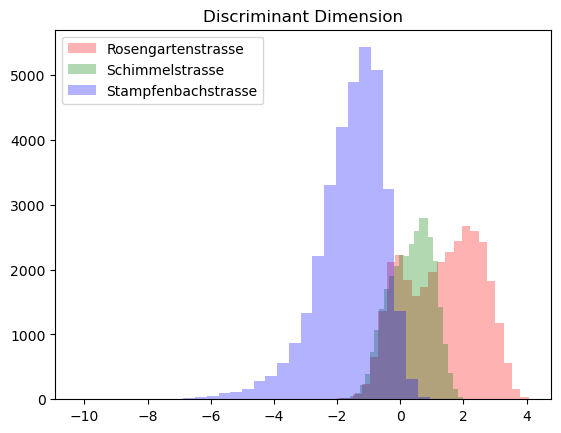

Explained variance ratio: [0.89638437]


In [35]:
# --- Step 1: Create 3 classes based on LDH_level --
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
# --- Step 2: Features and Target ---
key_cols = [c for c in ["Datetime", "YearMonth", "Year", "Month", "Date", "Time", "Location", "Location_Code"] if c in df_merged.columns]
feature_columns_names = [c for c in df_merged.columns if c not in key_cols]

#feature_columns_names = ['NO', 'NO2', 'NOx', 'O3', 'PM10', 'PM2.5', 'AnzFahrzeuge_daily_mean']

X = df_merged[feature_columns_names]
print(X)
y = df_merged['Location'].map({'Zch_Rosengartenstrasse': 0, 'Zch_Schimmelstrasse': 1, 'Zch_Stampfenbachstrasse': 2})

# --- Step 3: Train/Test Split ---

cutoff = 2022
train_mask = df_merged["Year"] < cutoff
test_mask  = df_merged["Year"] >= cutoff

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

# --- Step 4: LDA with 1 component ---
lda = LDA(n_components=1)
X_train1 = lda.fit_transform(X_train, y_train)

kwargs = dict(histtype='stepfilled', alpha=0.3, density=False, bins=30)

plt.hist(X_train1[y_train == 0].ravel(), **kwargs, label="Rosengartenstrasse", color='red')
plt.hist(X_train1[y_train == 1].ravel(), **kwargs, label="Schimmelstrasse", color='green')
plt.hist(X_train1[y_train == 2].ravel(), **kwargs, label="Stampfenbachstrasse", color='blue')
plt.legend()
plt.title("Discriminant Dimension")
plt.show()

print("Explained variance ratio:", lda.explained_variance_ratio_)


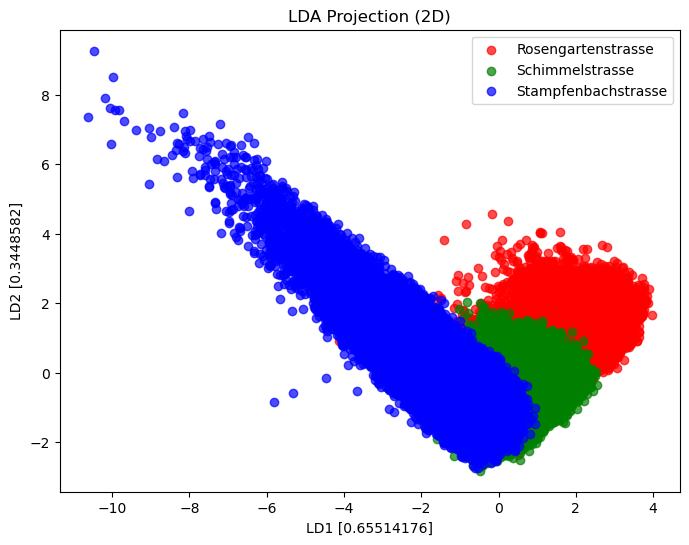

Explained variance ratio: [0.91190823 0.08809177]


In [47]:
# --- Step 2: Features and Target ---
key_cols = [c for c in ["Datetime", "YearMonth", "Year", "Month", "Date", "Time", "Location", "Location_Code"] if c in df_merged.columns]
feature_columns_names = [c for c in df_merged.columns if c not in key_cols]

X = df_merged[feature_columns_names]
y = df_merged['Location'].map({'Zch_Rosengartenstrasse': 0, 'Zch_Schimmelstrasse': 1, 'Zch_Stampfenbachstrasse': 2})

# --- Step 3: Train/Test Split ---

cutoff = 2024
train_mask = df_merged["Year"] < cutoff
test_mask  = df_merged["Year"] >= cutoff

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]


#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# --- Step 4: LDA with 2 components ---
lda = LDA(n_components=2)
X_train2 = lda.fit_transform(X_train, y_train)

# --- Step 5: Plot 2D LDA projection ---
plt.figure(figsize=(8,6))
colors = ['red', 'green', 'blue']
labels = ['Rosengartenstrasse', 'Schimmelstrasse', 'Stampfenbachstrasse']

for cls, color, label in zip([0, 1, 2], colors, labels):
    plt.scatter(X_train2[y_train == cls, 0], X_train2[y_train == cls, 1],
                alpha=0.7, label=label, color=color)

plt.xlabel('LD1 [0.65514176]')
plt.ylabel('LD2 [0.3448582]')
plt.title('LDA Projection (2D)')
plt.legend()
plt.show()

print("Explained variance ratio:", lda.explained_variance_ratio_)


=== PCA Loadings (signed) ===
        NO2      O3    PM10      Hr  RainDur       T     WVv  Weekday  \
PC1 -0.4010  0.5841 -0.1905 -0.4406  -0.0643  0.4364  0.2410   0.0565   
PC2  0.4281  0.0831  0.3579 -0.3969  -0.3321  0.2969 -0.3306  -0.0956   

     meanVehicles  
PC1       -0.1085  
PC2        0.4553  

=== PCA Loadings (absolute magnitude) ===
        NO2      O3    PM10      Hr  RainDur       T     WVv  Weekday  \
PC1  0.4010  0.5841  0.1905  0.4406   0.0643  0.4364  0.2410   0.0565   
PC2  0.4281  0.0831  0.3579  0.3969   0.3321  0.2969  0.3306   0.0956   

     meanVehicles  
PC1        0.1085  
PC2        0.4553  

--- PC1 loadings sorted by |loading| ---
              loading  abs_loading
O3             0.5841       0.5841
Hr            -0.4406       0.4406
T              0.4364       0.4364
NO2           -0.4010       0.4010
WVv            0.2410       0.2410
PM10          -0.1905       0.1905
meanVehicles  -0.1085       0.1085
RainDur       -0.0643       0.0643
Weekday  

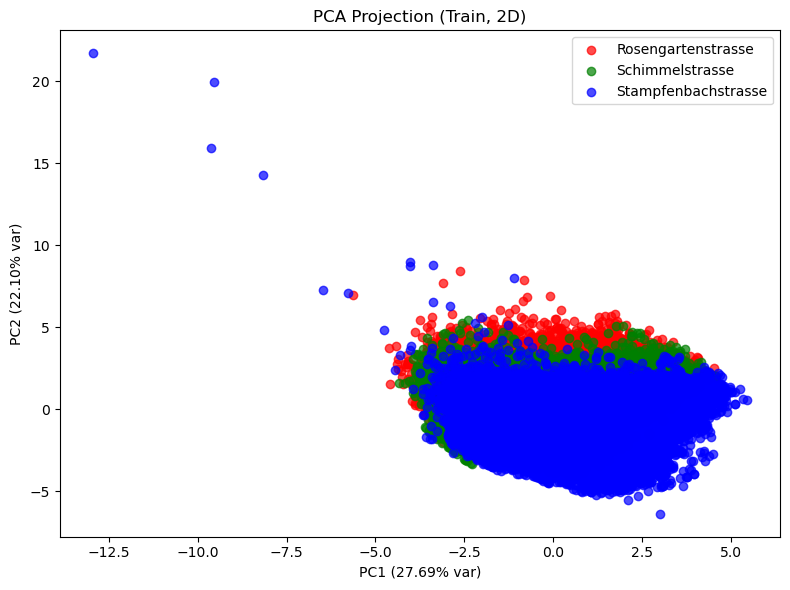

Explained variance ratio (train): [0.27690226 0.22095368]


In [49]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --- Step 1: Features and Target ---
key_cols = [c for c in ["Datetime", "YearMonth", "Year", "Month", "Date", "Time", "Location", "Location_Code"] if c in df_merged.columns]
feature_columns_names = [c for c in df_merged.columns if c not in key_cols]

X = df_merged[feature_columns_names]
y = df_merged['Location'].map({
    'Zch_Rosengartenstrasse': 0,
    'Zch_Schimmelstrasse': 1,
    'Zch_Stampfenbachstrasse': 2
})

# Optional: drop rows where y is NaN (unknown Location)
mask_known_y = ~y.isna()
X = X[mask_known_y]
y = y[mask_known_y]
df_year = df_merged.loc[mask_known_y, "Year"]

# --- Step 2: Train/Test Split by year ---
cutoff = 2024
train_mask = df_year < cutoff
test_mask  = df_year >= cutoff

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

# --- Step 3: Handle missing values (simple drop on train/test) ---
# (Alternatively, use imputation if you prefer)
X_train = X_train.dropna()
y_train = y_train.loc[X_train.index]

X_test  = X_test.dropna()
y_test  = y_test.loc[X_test.index]

# --- Step 4: Standardize features (important for PCA) ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# --- Step 5: PCA with 2 components ---
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)





# --- PC loading table ---
# Components: rows = PCs (PC1, PC2), columns = original features
loadings = pd.DataFrame(
    pca.components_,
    index=[f"PC{i+1}" for i in range(pca.n_components)],
    columns=feature_columns_names
)

# Also compute absolute loadings (strength)
abs_loadings = loadings.abs()

print("\n=== PCA Loadings (signed) ===")
print(loadings.round(4))

print("\n=== PCA Loadings (absolute magnitude) ===")
print(abs_loadings.round(4))

# --- Sorted views per PC (by absolute loading) ---
for i in range(pca.n_components):
    pc_name = f"PC{i+1}"
    sorted_pc = (
        loadings.loc[pc_name]
        .to_frame("loading")
        .assign(abs_loading=lambda df: df["loading"].abs())
        .sort_values("abs_loading", ascending=False)
    )
    print(f"\n--- {pc_name} loadings sorted by |loading| ---")
    print(sorted_pc.round(4))

# OPTIONAL: Create a neat table with both PCs in long form
long_table = (
    loadings.stack()
    .reset_index()
    .rename(columns={"level_0": "PC", "level_1": "Feature", 0: "Loading"})
)
long_table["AbsLoading"] = long_table["Loading"].abs()
print("\n=== Long-form loading table ===")
print(long_table.sort_values(["PC", "AbsLoading"], ascending=[True, False]).round(4))




# --- Step 6: Plot 2D PCA projection (train set) ---
plt.figure(figsize=(8, 6))
colors = ['red', 'green', 'blue']
labels = ['Rosengartenstrasse', 'Schimmelstrasse', 'Stampfenbachstrasse']

for cls, color, label in zip([0, 1, 2], colors, labels):
    pts = X_train_pca[y_train == cls]
    if pts.size == 0:
        continue
    plt.scatter(pts[:, 0], pts[:, 1], alpha=0.7, label=label, color=color)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} var)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} var)')
plt.title('PCA Projection (Train, 2D)')
plt.legend()
plt.tight_layout()
plt.show()

print("Explained variance ratio (train):", pca.explained_variance_ratio_)


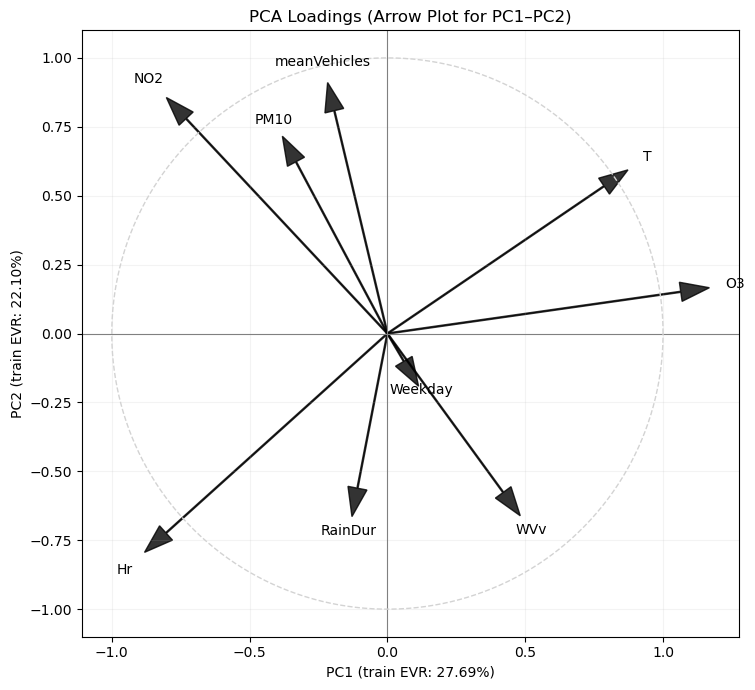

In [50]:
# Assumes you already have:
# - pca (fitted with n_components >= 2)
# - feature_columns_names = ['NO', 'NO2', 'NOx', 'O3', 'AnzFahrzeuge_daily_mean']

# Loadings matrix: rows = PCs, cols = features
loadings = pca.components_  # shape (n_components, n_features)

# Safety: ensure we have at least 2 components
if loadings.shape[0] < 2:
    raise ValueError("Need at least 2 principal components to create a 2D arrow plot.")

pc1, pc2 = loadings[0, :], loadings[1, :]

# Optional: scale arrows for visibility (purely aesthetic)
scale = 2.0  # tweak to your taste

plt.figure(figsize=(8, 7))
# Draw axes
plt.axhline(0, color='gray', lw=0.8)
plt.axvline(0, color='gray', lw=0.8)

# Draw arrows and annotate feature names
for i, feat in enumerate(feature_columns_names):
    x = pc1[i] * scale
    y = pc2[i] * scale
    plt.arrow(0, 0, x, y,
              color='black', alpha=0.8, width=0.004, head_width=0.07,
              length_includes_head=True)
    # Offset label slightly beyond arrow tip
    plt.text(x * 1.08, y * 1.08, feat, fontsize=10, ha='center', va='center')

# Optional: unit circle to help interpret correlation structure
# (When using standardized features, loadings approx. correlations)
theta = np.linspace(0, 2*np.pi, 400)
plt.plot(np.cos(theta), np.sin(theta), color='lightgray', ls='--', lw=1)

# Axis labels include train/test EVR you computed earlier
plt.xlabel(f'PC1 (train EVR: {pca.explained_variance_ratio_[0]:.2%}'
           + (f' | test EVR: {test_evr[0]:.2%}' if "test_evr" in globals() else '') + ')')
plt.ylabel(f'PC2 (train EVR: {pca.explained_variance_ratio_[1]:.2%}'
           + (f' | test EVR: {test_evr[1]:.2%}' if "test_evr" in globals() else '') + ')')

plt.title('PCA Loadings (Arrow Plot for PC1–PC2)')
plt.gca().set_aspect('equal', adjustable='box')
plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()


Preparation for: Time-Series Analysis

In [ ]:
CH_holidays = holidays.CountryHoliday('CH')

# feature extraction
df = df_merged.set_index(pd.to_datetime(df_merged["Datum_date"], errors="coerce"))
#df['count'] = df.sum(axis=1)
df['is_holiday'] = df.index.map(lambda x: x in CH_holidays )
df['dayofweek'] = df.index.map(lambda x: x.dayofweek)
df['year'] = df.index.map(lambda x: x.year)
df['month'] = df.index.map(lambda x: x.month)
df['dayofmonth'] = df.index.map(lambda x: x.day)

df

Which framing fits your research question?

“Which site is this observation from?” → Multiclass.

“Which exceedances/conditions are true at this time?” → Multilabel.

“Predict pollutant values themselves” → Regression (possibly multi-output if predicting several pollutants at once).

Analysis: Multiclass Classification - Q: "Which site is this ovservation from?"

In [ ]:
# 1) Prepare X, y (no scaling/assignment here)
feature_cols = ['NO','NO2','NOx','O3','AnzFahrzeuge_daily_mean','dayofweek','month','dayofmonth','is_holiday']
X = df[feature_cols].copy()
X['is_holiday'] = X['is_holiday'].astype(int)

y = df['Location'].map({
    'zch_rosengartenstrasse': 0,
    'zch_schimmelstrasse': 1,
    'zch_stampfenbachstrasse': 2
})

mask_known = ~y.isna()
X = X.loc[mask_known]
y = y.loc[mask_known].astype(int)

# 2) Split by year (keep rows aligned)
years = df.loc[mask_known, 'year']
train_mask = years < 2024
test_mask  = years >= 2024

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

# 3) Column-wise preprocessing
num_cols = ['NO','NO2','NOx','O3','AnzFahrzeuge_daily_mean','dayofweek','month','dayofmonth']
bin_cols = ['is_holiday']  # leave as-is

preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('bin', 'passthrough', bin_cols),
    ],
    remainder='drop'
)

# 4) Build pipeline
pipe = Pipeline(steps=[
    ('prep', preprocess),
    ('clf', LogisticRegression(max_iter=500))
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Rosengarten','Schimmel','Stampfenbach']))


Anlysis: Regression - Q: “Predict pollutant values themselves” (possibly multi-output if predicting several pollutants at once).

In [ ]:
# Milti-output regression to predict multiple pollutants simultaneously
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Choose your base model:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor

# -----------------------
# 1) Prepare data
# -----------------------
df_use = df.copy()

# Targets: predict pollutants
target_cols = ['NO', 'NO2', 'NOx', 'O3']
Y = df_use[target_cols].copy()

# Features: exclude targets to avoid leakage (use traffic + calendar + site)
feature_cols = [
    'AnzFahrzeuge_daily_mean',
    'dayofweek', 'month', 'dayofmonth',
    'is_holiday',          # bool → we’ll pass through as int
    'Location'             # categorical
]
X = df_use[feature_cols].copy()

# Ensure types are friendly
if X['is_holiday'].dtype == bool:
    X['is_holiday'] = X['is_holiday'].astype('int64')

# -----------------------
# 2) Time-aware split (by year groups)
# -----------------------
years = df_use['year']
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(gss.split(X, Y, groups=years))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
Y_train, Y_test = Y.iloc[train_idx], Y.iloc[test_idx]

# -----------------------
# 3) Preprocessing
# -----------------------
num_cols  = ['AnzFahrzeuge_daily_mean', 'dayofweek', 'month', 'dayofmonth', 'is_holiday']
cat_cols  = ['Location']

preprocess = ColumnTransformer(
    transformers=[
        # Numeric: impute → scale
        ('num', Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols),

        # Categorical: one-hot (handle unseen categories in test)
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ],
    remainder='drop'
)

# -----------------------
# 4) Choose model
# -----------------------
# A) Linear multi-output: Ridge can natively handle multi-output
base_model = Ridge(alpha=1.0, random_state=42)

# B) Tree-based: wrap regressor to handle multi-output
# base_model = MultiOutputRegressor(RandomForestRegressor(
#     n_estimators=300, random_state=42, n_jobs=-1
# ))

pipe = Pipeline(steps=[
    ('prep', preprocess),
    ('reg', base_model)
])

# -----------------------
# 5) Fit and predict
# -----------------------
pipe.fit(X_train, Y_train)
Y_pred = pipe.predict(X_test)
Y_pred = pd.DataFrame(Y_pred, index=Y_test.index, columns=target_cols)

# -----------------------
# 6) Evaluate
# -----------------------
def metrics_per_target(y_true_df, y_pred_df):
    out = []
    for col in y_true_df.columns:
        y_true = y_true_df[col].to_numpy()
        y_pred = y_pred_df[col].to_numpy()
        mae  = mean_absolute_error(y_true, y_pred)
        rmse = mean_squared_error(y_true, y_pred) #, squared=False)
        r2   = r2_score(y_true, y_pred)
        out.append((col, mae, rmse, r2))
    return pd.DataFrame(out, columns=['Target', 'MAE', 'RMSE', 'R2'])

results = metrics_per_target(Y_test, Y_pred)
print(results)

# Overall macro averages
print("\nMacro averages:")
print(results[['MAE','RMSE','R2']].mean())

# -----------------------
# 7) Optional: quick plots (matplotlib)
# -----------------------
import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=len(target_cols), ncols=1, figsize=(8, 2.8*len(target_cols)), sharex=True)
for ax, col in zip(axes, target_cols):
    ax.plot(Y_test.index, Y_test[col], label=f'True {col}', color='black', lw=1.2)
    ax.plot(Y_pred.index, Y_pred[col], label=f'Pred {col}', color='tab:blue', lw=1.2, alpha=0.8)
    ax.set_ylabel(col)
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Datum / index')
fig.suptitle('Multi-output regression: True vs. Predicted')
fig.tight_layout()
plt.show()


Analysis: Multilabel Classification - Q: “Which exceedances/conditions are true at this time?”

Multilabel classification based on exceedence of threshold (for NO2 and O3 so far) -> multiple violations at same time per location and day possible. There are other ways to 'artificially' create multilabel problem.

Below is an example turning the problem into multilabel by predicting two pollutant exceedances at once. Adjust thresholds to your domain (units assumed consistent with your data).

In [ ]:
# ---------- 1) Targets ----------
df_use = df.copy()

# Chosen thresholds (adjust to domain)
thr_no2 = 30   # µg/m³
thr_o3  = 10   # µg/m³

y_multi = pd.DataFrame({
    'NO2_exceed': (df_use['NO2'] > thr_no2).astype(int),
    'O3_exceed':  (df_use['O3']  > thr_o3 ).astype(int),
}, index=df_use.index)

# ---------- 2) Features ----------
feature_cols = [
    'NO', 'NO2', 'NOx', 'O3',
    'AnzFahrzeuge_daily_mean',
    'dayofweek', 'month', 'dayofmonth',
    'is_holiday'
]
X = df_use[feature_cols].copy()

# FIX 1 (dtype): create an explicit integer version if the original column is boolean
# (this avoids assigning ints into a bool column later)
if X['is_holiday'].dtype == bool:
    X['is_holiday_int'] = X['is_holiday'].astype('int64')
    X = X.drop(columns=['is_holiday'])
    bin_cols = ['is_holiday_int']
else:
    bin_cols = ['is_holiday']  # already numeric

# ---------- 3) Year group split ----------
years = df_use['year']
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(gss.split(X, y_multi, groups=years))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y_multi.iloc[train_idx], y_multi.iloc[test_idx]

# ---------- 4) Column-wise preprocessing ----------
num_cols = ['NO', 'NO2', 'NOx', 'O3', 'AnzFahrzeuge_daily_mean', 'dayofweek', 'month', 'dayofmonth']

preprocess = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols),
        ('bin', 'passthrough', bin_cols),
    ],
    remainder='drop'
)

# ---------- 5) Model ----------
base_clf = LogisticRegression(max_iter=300, class_weight='balanced')
ovr = OneVsRestClassifier(base_clf)

pipe = Pipeline(steps=[
    ('prep', preprocess),
    ('clf', ovr)
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

# ---------- 6) Metrics (avoid undefined warnings) ----------
print("Hamming loss (lower is better):", hamming_loss(y_test, y_pred))
print("Jaccard micro:", jaccard_score(y_test, y_pred, average='micro'))
print("Jaccard macro:", jaccard_score(y_test, y_pred, average='macro'))

# Set zero_division=0 to avoid warnings when samples have zero true/predicted labels
print("\nPer-label report:\n",
      classification_report(y_test, y_pred, target_names=y_multi.columns, zero_division=0))

# ---------- 7) Optional: threshold tuning to reduce all-zero predictions ----------
# Default .predict uses threshold 0.5. You can lower thresholds if too many all-zero predictions occur.
#if hasattr(pipe, "predict_proba"):
#    y_proba = pipe.predict_proba(X_test)  # shape (n_samples, n_labels)
#    # Example: slightly lower thresholds to reduce zero predictions
#    thresholds = np.array([0.45, 0.45])  # tune per label
#    y_pred_tuned = (y_proba >= thresholds).astype(int)

#    print("\n(Tuned thresholds)")
#    print("Hamming loss:", hamming_loss(y_test, y_pred_tuned))
#    print("Jaccard micro:", jaccard_score(y_test, y_pred_tuned, average='micro'))
#    print("Jaccard macro:", jaccard_score(y_test, y_pred_tuned, average='macro'))
#    print("\nPer-label report (tuned):\n",
#          classification_report(y_test, y_pred_tuned, target_names=y_multi.columns, zero_division=0))

Analysis: Time-Series

In [ ]:
def plot_multiplot(y):
    figure, ((ax1, ax2), (ax3, ax4)) = plt.subplots(nrows=2, ncols=2)
    figure.set_size_inches(12, 8)
    sns.pointplot(data=df, x='dayofmonth', y=y, hue='year', ax=ax1)
    sns.pointplot(data=df, x='month', y=y, hue='year', ax=ax2)
    sns.boxplot(data=df, x='year', y=y, ax=ax3)
    sns.pointplot(data=df, x='dayofweek', y=y, hue='year', ax=ax4)    

In [ ]:
plot_multiplot('NO')

In [ ]:
plot_multiplot('NO2')

In [ ]:
plot_multiplot('NOx')

In [ ]:
plot_multiplot('O3')

In [ ]:
import plotly.graph_objs as go
fig = go.Figure(
    [
        go.Scatter(x=df.index, y=df['NO'], name='NO', line=dict(width=0.8)),
        go.Scatter(x=df.index, y=df['NO2'], name='NO2', line=dict(width=0.8)),
        go.Scatter(x=df.index, y=df['NOx'], name='NOx', line=dict(width=0.8)),
        go.Scatter(x=df.index, y=df['O3'], name='O3', line=dict(width=0.8)),
        #go.Scatter(x=df.index, y=df['AnzFahrzeuge_daily_mean'], name='AnzFahrzeuge_daily_mean', line=dict(width=0.8, dash='dot')),
        go.Scatter(x=df.loc[df.is_holiday].index, y=df.loc[df.is_holiday]['NO2'], mode='markers', name='holiday'),
    ])
fig.update_xaxes(
    rangeslider_visible=True
)
fig.show()

In [ ]:

import pandas as pd
import plotly.express as px

# Ensure your index is a datetime for the x-axis
#df = df.copy()
#df = df.reset_index().rename(columns={"index": "Datum"})  # adjust if index name is different

# Melt to long format: one row per (Datum, Location, pollutant)
long_df = df.melt(
    id_vars=["Datum_date", "Location", "is_holiday"],  # keep date/site/holiday flags
    value_vars=["NO", "NO2", "NOx", "O3"], #"AnzFahrzeuge_daily_mean"],        # pollutants
    var_name="Pollutant", value_name="Value"
)

# Facet by Location, color by pollutant
fig = px.line(
    long_df,
    x="Datum_date", y="Value",
    color="Pollutant",
    facet_col="Location",         # each Location gets its own panel (column)
    facet_col_wrap=2,             # wrap panels after 2 columns if many Locatione
    height=600
)

# Optional: add holiday markers per facet
holiday_df = long_df[long_df["is_holiday"] & (long_df["Pollutant"] == "NO2")]
fig.add_scatter(
    x=holiday_df["Datum_date"],
    y=holiday_df["Value"],
    mode="markers",
    name="Holiday (NO2)",
    marker=dict(size=6, color="orange"), #symbol="circle-open"),
    showlegend=True
)

# Thinner lines
fig.update_traces(line=dict(width=0.8), selector=dict(type="scatter", mode="lines"))

# Rangeslider across all facets (note: rangeslider shows only on bottom x-axis)
fig.update_xaxes(rangeslider_visible=True)

# Improve layout
#fig.update_layout(
#    legend_title_text="Pollutant",
#    title="Pollutants over time faceted by Location",
#    margin=dict(l=40, r=20, t=60, b=40)
#)

fig.show()


In [ ]:

import pandas as pd
import plotly.express as px

# Ensure your index is a datetime for the x-axis
#df = df.copy()
#df = df.reset_index().rename(columns={"index": "Datum"})  # adjust if index name is different

# Melt to long format: one row per (Datum, Location, pollutant)
long_df = df.melt(
    id_vars=["Datum_date", "Location", "is_holiday"],  # keep date/site/holiday flags
    value_vars=["AnzFahrzeuge_daily_mean"],        # pollutants
    var_name="Pollutant", value_name="Value"
)

# Facet by Location, color by pollutant
fig = px.line(
    long_df,
    x="Datum_date", y="Value",
    color="Pollutant",
    facet_col="Location",         # each Location gets its own panel (column)
    facet_col_wrap=2,             # wrap panels after 2 columns if many Locatione
    height=600
)

# Optional: add holiday markers per facet
holiday_df = long_df[long_df["is_holiday"] & (long_df["Pollutant"] == "NO2")]
fig.add_scatter(
    x=holiday_df["Datum_date"],
    y=holiday_df["Value"],
    mode="markers",
    name="Holiday (NO2)",
    marker=dict(size=6, color="black", symbol="circle-open"),
    showlegend=True
)

# Thinner lines
fig.update_traces(line=dict(width=0.8), selector=dict(type="scatter", mode="lines"))

# Rangeslider across all facets (note: rangeslider shows only on bottom x-axis)
fig.update_xaxes(rangeslider_visible=True)

# Improve layout
#fig.update_layout(
#    legend_title_text="Pollutant",
#    title="Pollutants over time faceted by Location",
#    margin=dict(l=40, r=20, t=60, b=40)
#)

fig.show()
